In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

data = pd.read_csv('../Data/creditcard_clean.csv')

## Pick the best feature (highest correlation with Amount)

In [2]:
v_cols = ['V' + str(i) for i in range(1, 29)]

corr = data[v_cols + ['Amount']].corr()['Amount'].drop('Amount')
best_feat = corr.abs().idxmax()

print(corr.abs().sort_values(ascending=False).head(5))
print('Best feature:', best_feat)

V2     0.533428
V7     0.400408
V5     0.387685
V20    0.340729
V1     0.230105
Name: Amount, dtype: float64
Best feature: V2


## Train-test split

In [3]:
x = data[v_cols]
y = data['Amount']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

## 1. Simple Linear Regression (one feature)

R2 score: 0.30410296618371757


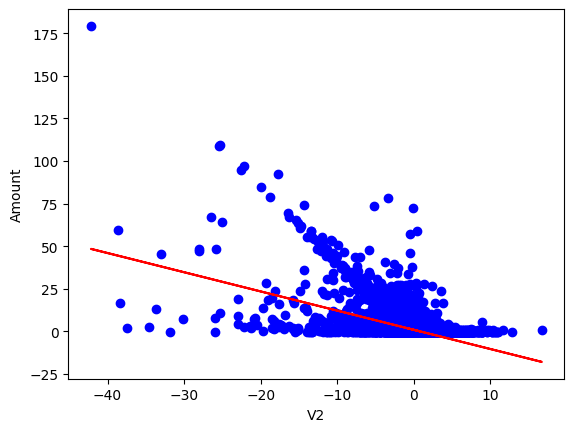

In [8]:
model = LinearRegression()
model.fit(x_train[[best_feat]], y_train)
y_pred = model.predict(x_test[[best_feat]])

print('R2 score:', r2_score(y_test, y_pred))

plt.scatter(x_test[best_feat], y_test, color='blue')
plt.plot(x_test[best_feat], y_pred, color='red')
plt.xlabel(best_feat)
plt.ylabel('Amount')
plt.show()

## 2. Multiple Linear Regression (all V features)

In [5]:
model = LinearRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

print('R2 score:', r2_score(y_test, y_pred))

R2 score: 0.916833976214606


## 3. Polynomial Regression (degree 2, best feature)

In [6]:
x1_train = x_train[[best_feat]]
x1_test = x_test[[best_feat]]

poly = PolynomialFeatures(degree=2)
x_train_trans = poly.fit_transform(x1_train)
x_test_trans = poly.transform(x1_test)

model = LinearRegression()
model.fit(x_train_trans, y_train)
y_pred = model.predict(x_test_trans)

print('R2 train:', r2_score(y_train, model.predict(x_train_trans)))
print('R2 test :', r2_score(y_test, y_pred))

R2 train: 0.29887473070599735
R2 test : 0.3250440395609676
